# Can they afford to repay? Affordability-based default risk

Credit scores look backwards: they summarise how someone has handled debt before. Affordability asks
whether the repayments fit the borrower's income and existing commitments. This notebook tests, on real
Lending Club loans, whether affordability measures predict default as well as the credit score and bureau
record, and whether they add anything on top of them.

**Outcome.** Default within 24 months of issue. A loan counts as defaulted if it was charged off and its
default date (last payment plus four months, roughly 90+ days past due) falls inside the window. Only loans
whose whole 24-month window had passed by the data snapshot (March 2019) are used, so recent loans are not
scored on an outcome that has not happened yet. Earlier versions kept only finished loans, which
over-represents defaults in recent vintages because the loans still running are mostly the good ones.

**Test.** Models are trained on loans issued up to 2014 and tested on loans issued in 2015-2016, so the
test is on later borrowers the model never saw. The data is built by `build_dataset.py` from the raw file.

In [1]:
from IPython.display import Image, display  # shows the saved figures inline

In [2]:
import pandas as pd, numpy as np, matplotlib
matplotlib.use("Agg"); import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from scipy.stats import ks_2samp
from xgboost import XGBClassifier
import shap, warnings, json, os; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 120
RND = 42

# Built by build_dataset.py. Every accepted loan is kept; the outcome is default within a fixed
# 24-month window, used only for loans whose whole window was observable by the snapshot.
# (Earlier versions kept only finished loans, which over-represents defaults in recent vintages.)
WINDOW = 24
df_all = pd.read_parquet(os.environ.get("AFFORDABILITY_PARQUET", "data/lending_affordability.parquet"))
df = df_all[df_all[f"obs_{WINDOW}"]].copy()
df["default"] = df[f"bad_{WINDOW}"].astype(int)          # default within 24 months of issue
base = df["default"].mean()
print(f"Loans with an observable {WINDOW}-month outcome: {len(df):,} of {len(df_all):,} | "
      f"{WINDOW}-month default rate: {base:.1%} | issued {int(df['issue_year'].min())}-{int(df['issue_year'].max())}")

AFFORD = ["annual_inc_eff","dti_eff","payment_to_income","loan_to_income","installment","loan_amnt","term_months","emp_length_num"]
CREDIT = ["fico","delinq_2yrs","inq_last_6mths","revol_util","open_acc","pub_rec","total_acc","credit_history_yrs"]
BOTH = AFFORD + CREDIT

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loans with an observable 24-month outcome: 1,218,296 of 2,260,662 | 24-month default rate: 10.8% | issued 2007-2016


## 1. The affordability gradient
Default rate by three affordability measures: the annual loan payment as a share of income, the
debt-to-income ratio (using the joint figures for joint applications), and the loan size as a share of income.

In [3]:
# ---------------- FIG 1: the affordability gradient ----------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
def gradient(col, bins, labels, axis, xlabel):
    g = df.groupby(pd.cut(df[col], bins=bins, labels=labels))["default"].mean()
    g.plot(kind="bar", ax=axis, color="#c44e52"); axis.axhline(base, ls="--", color="black", label=f"overall {base:.0%}")
    axis.set_xlabel(xlabel); axis.set_ylabel("default rate"); axis.legend(); axis.tick_params(axis="x", rotation=0)
gradient("payment_to_income", [0,.05,.10,.15,.20,2], ["<5%","5-10%","10-15%","15-20%",">20%"], ax[0], "annual loan payment / income")
gradient("dti_eff", [0,10,20,30,40,100], ["<10","10-20","20-30","30-40",">40"], ax[1], "debt-to-income (DTI)")
gradient("loan_to_income", [0,.1,.2,.3,.5,5], ["<10%","10-20%","20-30%","30-50%",">50%"], ax[2], "loan size / income")
fig.suptitle("The affordability gradient: the more of someone's income a loan consumes, the more they default", fontsize=12)
plt.tight_layout(); plt.savefig("figures/01_affordability_gradient.png"); plt.close()
print("\nDefault rate by payment-to-income:")
print(df.groupby(pd.cut(df["payment_to_income"], [0,.05,.10,.15,.20,2], labels=["<5%","5-10%","10-15%","15-20%",">20%"]))["default"].mean().round(3).to_string())


Default rate by payment-to-income:
payment_to_income
<5%       0.077
5-10%     0.102
10-15%    0.140
15-20%    0.165
>20%      0.204


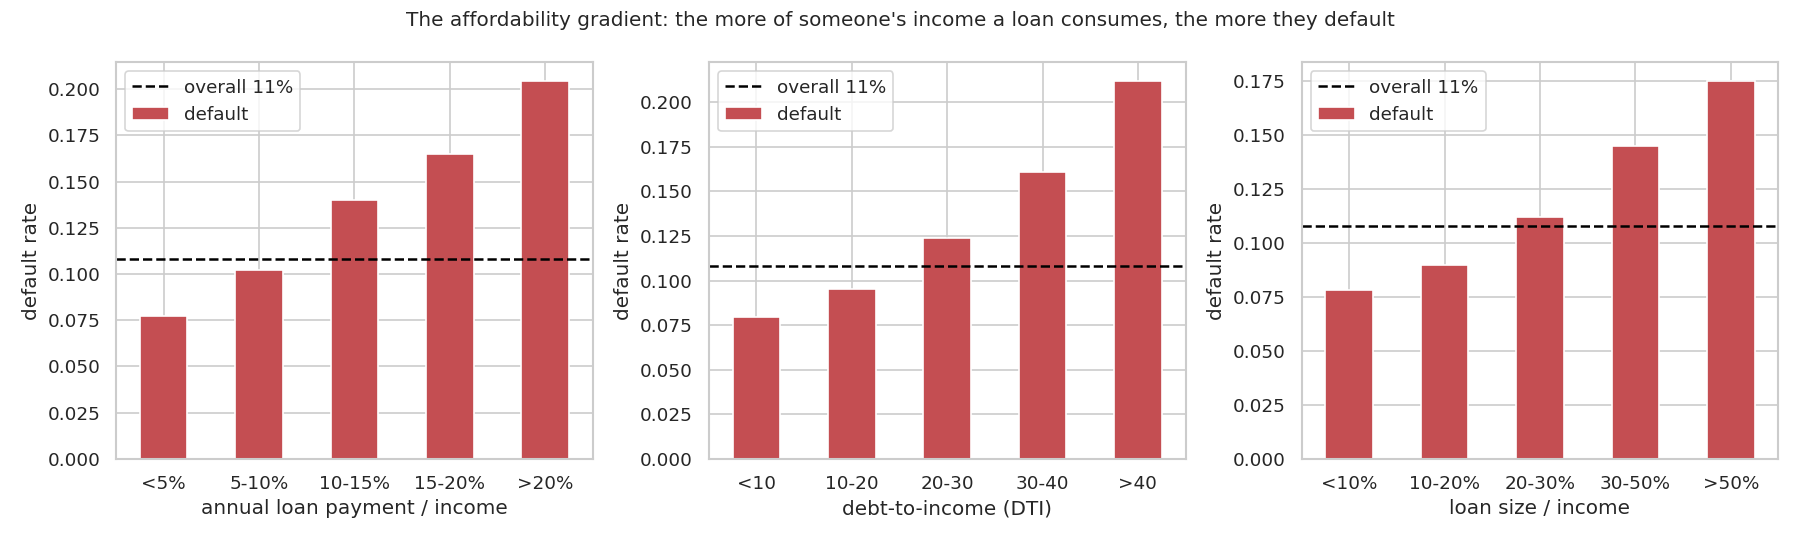

In [4]:
display(Image(filename="figures/01_affordability_gradient.png"))

## 2. Affordability within the same credit score
If affordability only repeated what the credit score already says, default would be flat across DTI
within a FICO band. The heatmap holds FICO fixed and varies DTI.

In [5]:
# ---------------- FIG 2: affordability adds signal BEYOND the credit score ----------------
fico_bins = [660,680,700,720,740,760,850]; fico_lab = ["660-680","680-700","700-720","720-740","740-760","760+"]
dti_bins = [0,10,20,30,40,100];           dti_lab = ["<10","10-20","20-30","30-40",">40"]
piv = df.assign(fb=pd.cut(df["fico"],fico_bins,labels=fico_lab), db=pd.cut(df["dti_eff"],dti_bins,labels=dti_lab)) \
        .groupby(["fb","db"])["default"].mean().unstack()
plt.figure(figsize=(9,6))
sns.heatmap(piv*100, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label":"default rate (%)"})
plt.xlabel("debt-to-income (affordability)"); plt.ylabel("FICO score (creditworthiness)")
plt.title("Even at the same credit score, worse affordability means more default")
plt.tight_layout(); plt.savefig("figures/02_fico_vs_affordability.png"); plt.close()
print("\nWithin FICO 700-720, default rate by DTI:"); print((piv.loc["700-720"]*100).round(0).to_string())


Within FICO 700-720, default rate by DTI:
db
<10       7.0
10-20     8.0
20-30    10.0
30-40    13.0
>40      19.0


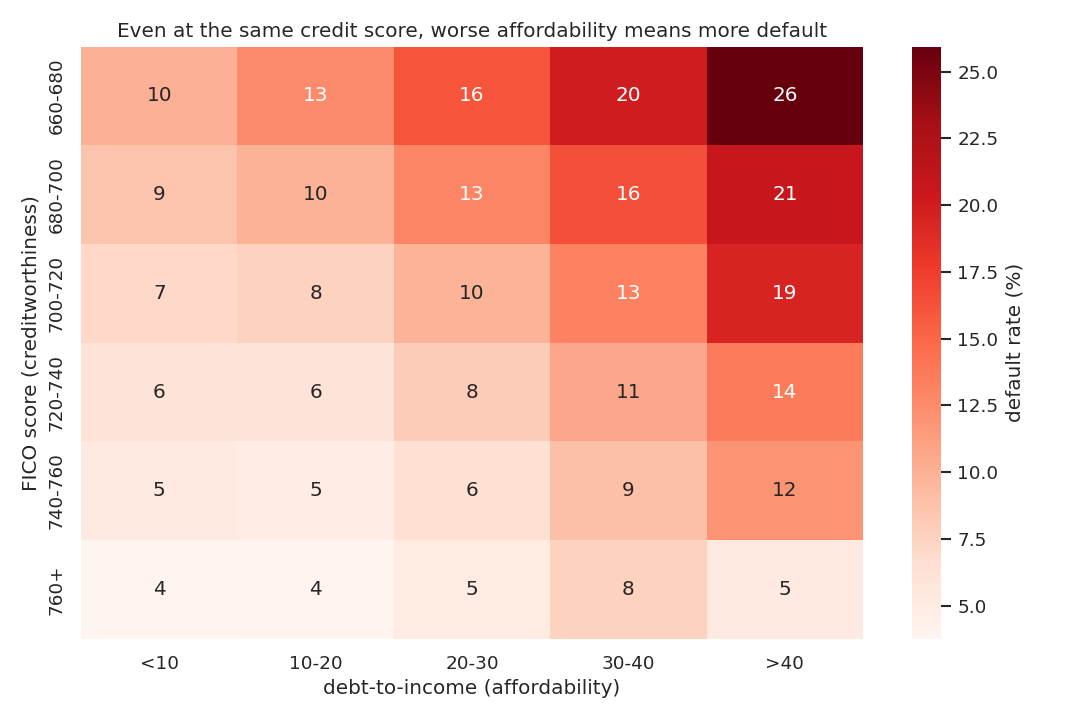

In [6]:
display(Image(filename="figures/02_fico_vs_affordability.png"))

## 3. Out-of-time test: credit score vs affordability vs both
The same XGBoost settings are trained on three feature sets, so any difference comes from the features.
The credit set is FICO plus bureau fields; the affordability set is income, DTI, payment and loan size
measures. Lending Club's own grade and interest rate are left out because they already encode its risk view.
With roughly one loan in nine defaulting, PR-AUC is reported next to ROC-AUC; a model with no skill scores
the default rate.

In [7]:
# ---------------- MODELS: credit-only vs affordability-only vs both ----------------
# Out-of-time split: train on loans issued up to 2014, test on later loans the model never saw.
dev, oot = df["issue_year"] <= 2014, df["issue_year"] >= 2015
Xtr, Xte, ytr, yte = df.loc[dev, BOTH], df.loc[oot, BOTH], df.loc[dev, "default"], df.loc[oot, "default"]
print(f"\nOut-of-time split: train {dev.sum():,} loans issued <=2014 ({ytr.mean():.1%} default) | "
      f"test {oot.sum():,} loans issued 2015-{int(df.loc[oot, 'issue_year'].max())} ({yte.mean():.1%} default)")
spw = (ytr==0).sum()/(ytr==1).sum()
def run(feats, name):
    m = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
                      scale_pos_weight=spw, eval_metric="aucpr", tree_method="hist", random_state=RND, n_jobs=4)
    m.fit(Xtr[feats], ytr); p = m.predict_proba(Xte[feats])[:,1]
    auc, ap = roc_auc_score(yte,p), average_precision_score(yte,p)
    print(f"  {name:24s} ROC-AUC {auc:.3f} | PR-AUC {ap:.3f}")
    return m, p, auc, ap
print(f"\nPredicting {WINDOW}-month default, out of time (no-skill PR-AUC = {yte.mean():.3f}):")
m_cr, p_cr, auc_cr, ap_cr = run(CREDIT, "Credit score + bureau")
m_af, p_af, auc_af, ap_af = run(AFFORD, "Affordability only")
m_bo, p_bo, auc_bo, ap_bo = run(BOTH,   "Both combined")


Out-of-time split: train 466,340 loans issued <=2014 (9.4% default) | test 751,956 loans issued 2015-2016 (11.6% default)

Predicting 24-month default, out of time (no-skill PR-AUC = 0.116):


  Credit score + bureau    ROC-AUC 0.620 | PR-AUC 0.166


  Affordability only       ROC-AUC 0.683 | PR-AUC 0.216


  Both combined            ROC-AUC 0.683 | PR-AUC 0.218


### Comparing the three models

In [8]:
# ---------------- FIG 3: model comparison ----------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p, c in [("Credit score + bureau", p_cr, "#4c72b0"), ("Affordability only", p_af, "#dd8452"), ("Both combined", p_bo, "#55a868")]:
    fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, c=c, label=f"{name} (AUC {roc_auc_score(yte,p):.3f})")
ax[0].plot([0,1],[0,1],"k--",lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
lift = auc_bo - auc_af
ax[0].set_title("Affordability outranks the credit score; " + ("combining adds a little more" if lift >= 0.005 else "bureau data adds little on top"))
ax[0].legend()
comp = pd.DataFrame({"ROC-AUC":[auc_cr,auc_af,auc_bo],"PR-AUC":[ap_cr,ap_af,ap_bo]},
                    index=["Credit\n+bureau","Afford-\nability","Both"])
comp.plot(kind="bar", ax=ax[1], color=["#4c72b0","#55a868"]); ax[1].set_ylabel("score"); ax[1].set_ylim(0,max(auc_bo,0.75)*1.1)
ax[1].axhline(yte.mean(), ls=":", color="grey", label=f"no-skill PR-AUC ({yte.mean():.2f})")
ax[1].set_title("Affordability adds real predictive power"); ax[1].tick_params(axis="x", rotation=0); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/03_model_comparison.png"); plt.close()
print(f"\nAffordability-only AUC ({auc_af:.3f}) vs credit-only ({auc_cr:.3f}); combined {auc_bo:.3f} ({lift:+.3f} over affordability alone)")


Affordability-only AUC (0.683) vs credit-only (0.620); combined 0.683 (+0.001 over affordability alone)


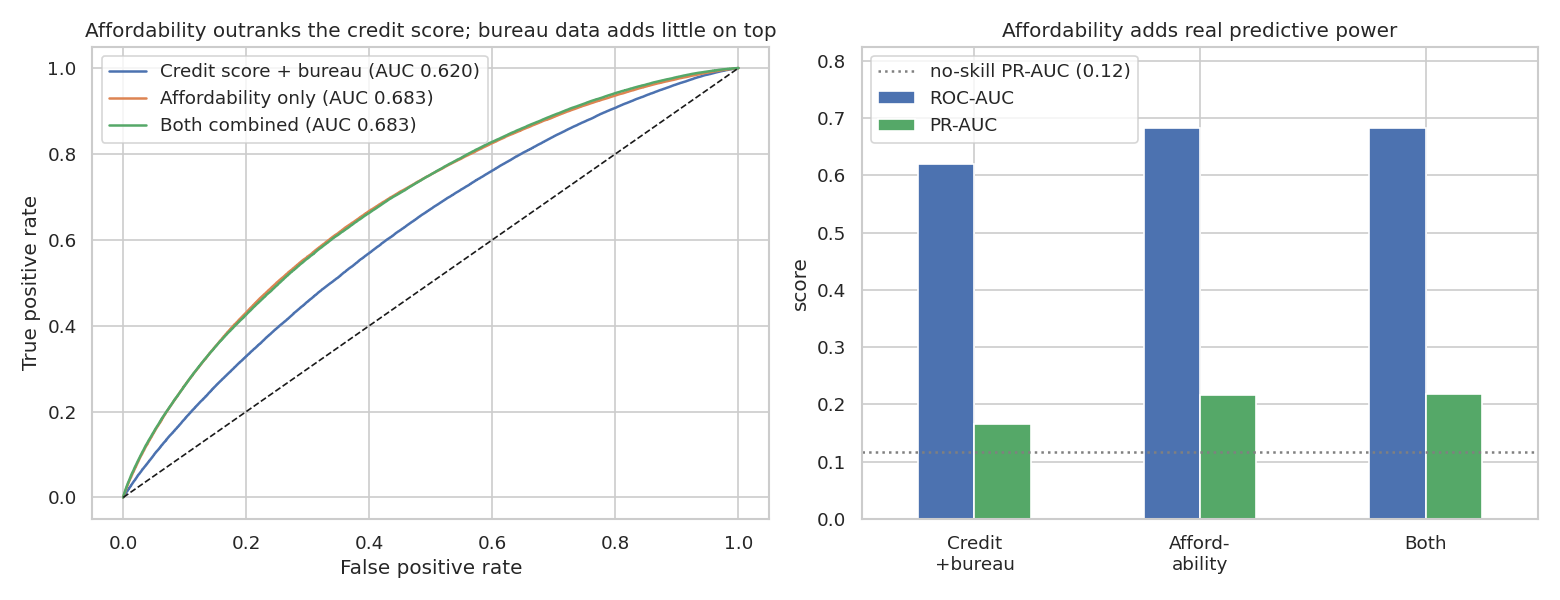

In [9]:
display(Image(filename="figures/03_model_comparison.png"))

## 4. What the combined model relies on
SHAP values on 3,000 test loans. They show how the model uses each feature, not cause and effect: term
length, for example, partly reflects who chooses a 60-month loan.

In [10]:
# ---------------- FIG 4: what drives default (SHAP, combined model) ----------------
samp = Xte.sample(3000, random_state=RND); sv = shap.TreeExplainer(m_bo).shap_values(samp)
plt.figure(); shap.summary_plot(sv, samp, show=False, max_display=12)
plt.title("What predicts default: affordability and credit signals together (SHAP)", fontsize=11)
plt.tight_layout(); plt.savefig("figures/04_shap_summary.png", bbox_inches="tight"); plt.close()
imp = pd.Series(np.abs(sv).mean(0), index=samp.columns).sort_values(ascending=False)
print("\nTop default drivers (mean |SHAP|):"); print(imp.head(8).round(3).to_string())


Top default drivers (mean |SHAP|):
payment_to_income    0.270
term_months          0.265
fico                 0.239
inq_last_6mths       0.147
loan_amnt            0.136
installment          0.122
dti_eff              0.116
loan_to_income       0.111


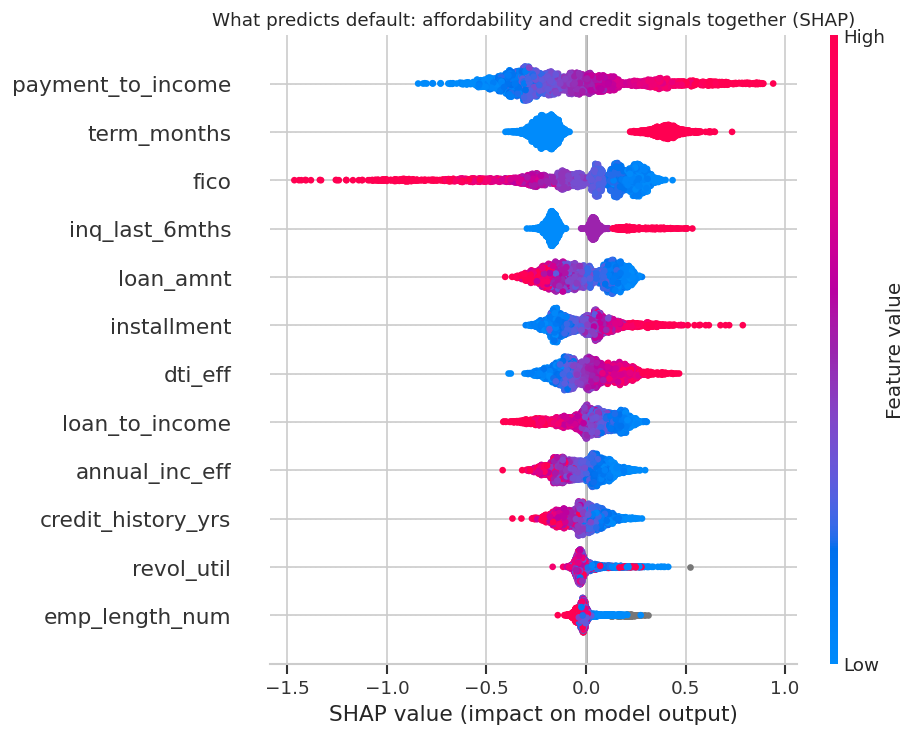

In [11]:
display(Image(filename="figures/04_shap_summary.png"))

## 5. Income on its own

In [12]:
# ---------------- FIG 5: lower income, higher default ----------------
dec = df.groupby(pd.qcut(df["annual_inc_eff"], 10, labels=False))["default"].mean()
plt.figure(figsize=(8,5))
plt.plot(range(1,11), dec.values*100, "o-", color="#8172b3")
plt.axhline(base*100, ls="--", color="black", label=f"overall {base:.0%}")
plt.xlabel("income decile (1 = lowest, 10 = highest)"); plt.ylabel("default rate (%)")
plt.title("Default falls steadily as income rises"); plt.legend(); plt.xticks(range(1,11))
plt.tight_layout(); plt.savefig("figures/05_income_gradient.png"); plt.close()

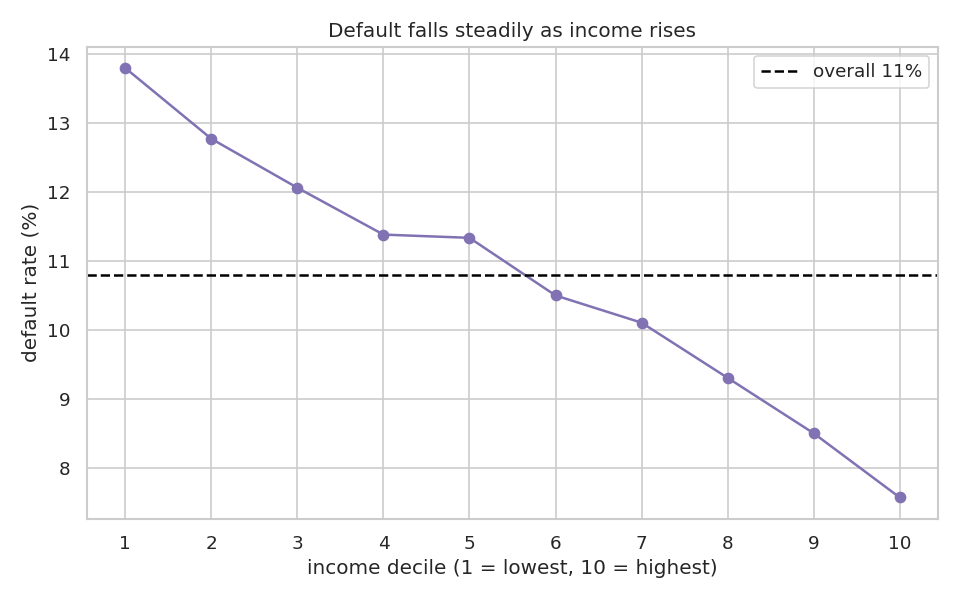

In [13]:
display(Image(filename="figures/05_income_gradient.png"))

## 6. How well the combined model separates outcomes
KS is the largest gap between the cumulative score distributions of loans that defaulted and loans that did not.

In [14]:
# ---------------- FIG 6: score separation (combined model) ----------------
ks = ks_2samp(p_bo[yte==1], p_bo[yte==0]).statistic
plt.figure(figsize=(8,5))
sns.kdeplot(p_bo[yte==0], fill=True, color="#4c72b0", label="Repaid", clip=(0,1))
sns.kdeplot(p_bo[yte==1], fill=True, color="#c44e52", label="Defaulted", clip=(0,1))
plt.xlabel("predicted default risk"); plt.ylabel("density")
plt.title(f"The combined model separates outcomes (KS = {ks:.2f})"); plt.legend()
plt.tight_layout(); plt.savefig("figures/06_score_separation.png"); plt.close()
print(f"\nCombined-model KS statistic = {ks:.3f}")


Combined-model KS statistic = 0.264


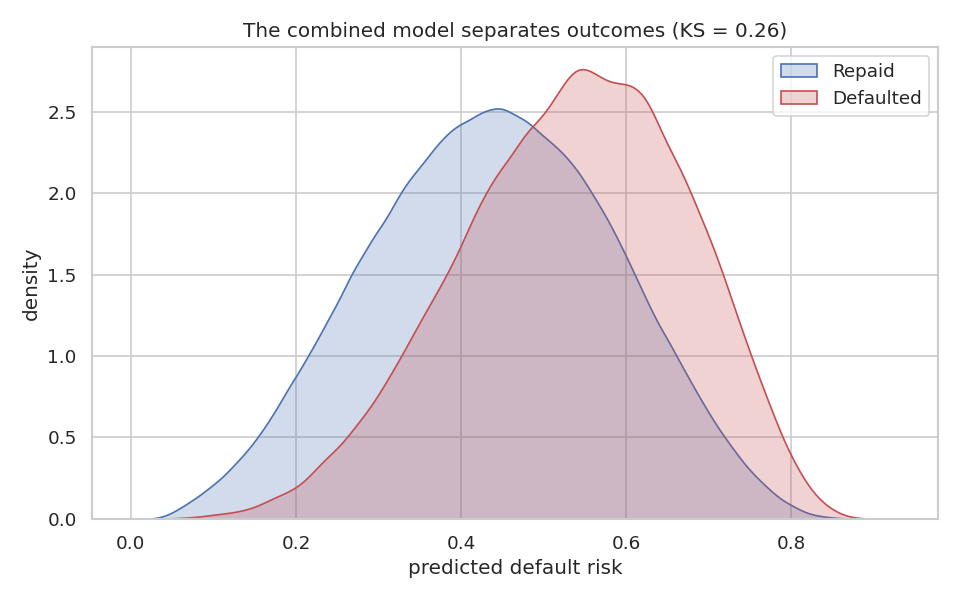

In [15]:
display(Image(filename="figures/06_score_separation.png"))

## 7. A random split, for comparison only
Earlier versions tested on a random 25% of loans. Mixing years lets the model see the same economic
conditions in training and test, so a random split usually flatters it. It is kept here only to show the
size of that effect; the out-of-time results above are the ones to quote.

In [16]:
# ---------------- random split, for comparison with earlier versions only ----------------
rXtr, rXte, rytr, ryte = train_test_split(df[BOTH], df["default"], test_size=0.25, stratify=df["default"], random_state=RND)
random_split = {}
for feats, name in [(CREDIT, "credit"), (AFFORD, "affordability"), (BOTH, "both")]:
    m = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8,
                      scale_pos_weight=(rytr == 0).sum() / (rytr == 1).sum(), eval_metric="aucpr",
                      tree_method="hist", random_state=RND, n_jobs=4).fit(rXtr[feats], rytr)
    random_split[name] = round(float(roc_auc_score(ryte, m.predict_proba(rXte[feats])[:, 1])), 3)
print(f"\nFor comparison, a random split gives ROC-AUC {random_split}")


For comparison, a random split gives ROC-AUC {'credit': 0.624, 'affordability': 0.683, 'both': 0.69}


## Save the results
Every number quoted in the README comes from `results.json`, written here.

In [17]:
g = df.groupby(pd.cut(df["payment_to_income"], [0, .05, .10, .15, .20, 2],
               labels=["<5%", "5-10%", "10-15%", "15-20%", ">20%"]), observed=False)["default"].mean()
results = dict(window_months=WINDOW, loans_all=int(len(df_all)), loans_observable=int(len(df)),
               default_rate=round(float(base), 4),
               issued=f"{int(df['issue_year'].min())}-{int(df['issue_year'].max())}",
               train=dict(n=int(dev.sum()), issued="<=2014", default_rate=round(float(ytr.mean()), 4)),
               test=dict(n=int(oot.sum()), issued=f"2015-{int(df.loc[oot, 'issue_year'].max())}",
                         default_rate=round(float(yte.mean()), 4)),
               out_of_time=dict(credit=dict(roc_auc=round(auc_cr, 3), pr_auc=round(ap_cr, 3)),
                                affordability=dict(roc_auc=round(auc_af, 3), pr_auc=round(ap_af, 3)),
                                both=dict(roc_auc=round(auc_bo, 3), pr_auc=round(ap_bo, 3)), ks_both=round(float(ks), 3)),
               random_split_roc_auc=random_split,
               default_rate_by_payment_to_income={k: round(float(v), 4) for k, v in g.items()})
json.dump(results, open("results.json", "w"), indent=2)
print("\nAll figures and results.json saved. DONE.")


All figures and results.json saved. DONE.


## Limitations
- **Approved loans only.** Lending Club had already declined the riskiest applicants, so the credit score's
  range is narrow here (most borrowers sit between 660 and 720). That weakens the credit-only model and
  means the results do not describe a full applicant population.
- **Default date is approximate.** It is set at last payment plus four months, because the file has no
  delinquency history.
- **One test period.** The out-of-time test covers 2015-2016 issues, a single benign US credit period.
- **Stated income.** Income is self-reported and only partly verified, so affordability is measured with noise.